# Weights of Evidence (WOE) — An Alternative to Dummy Encoding

A credit scoring case. This notebook illustrates **weights-of-evidence (WOE) encoding** as an alternative to dummy encoding, together with the **information value (IV)** that measures the predictive power of a variable and that drives the choice of the categories. It covers:

- **Section 2 — WOE and IV:** how they are calculated, illustrated on a categorical variable (`housing`)
- **Section 3 — a continuous variable** (`age`): turning it into categories with *IV-driven binning*, increasing the number of bins step by step and monitoring the IV to decide on the number of bins
- **Section 4 — a categorical variable** (`purpose`): *regrouping* its many categories into a few groups in the same way
- **Section 5 — WOE encoding:** replacing both variables by their WOE values
- **Section 6 — WOE versus dummy encoding:** how many parameters a logistic regression needs, and how it performs

The notation follows the course slides:

- *Goods* are customers who repay, *bads* are customers who default.
- *Distr. Goods* of a category = the share of all goods that falls in that category; likewise *Distr. Bads*.
- $\text{WOE}_{\text{category}} = \ln\left(\dfrac{\text{Distr. Goods}}{\text{Distr. Bads}}\right) \times 100$ — positive when the category contains relatively more goods than bads (lower risk), negative when it contains relatively more bads (higher risk).
- $\text{IV} = \sum_{\text{category}} \left(\text{Distr. Goods} - \text{Distr. Bads}\right) \times \dfrac{\text{WOE}}{100}$
- Rule of thumb for the IV of a variable: below 0.02 *unpredictive*, 0.02–0.1 *weak*, 0.1–0.3 *medium*, above 0.3 *strong*.

### Dataset
We use the **German Credit data** (Statlog German Credit Data, UCI Machine Learning Repository; OpenML name `credit-g`): 1,000 loan applicants described by 20 attributes — 7 numeric and 13 categorical — labelled *good* (700) or *bad* (300). It is loaded below straight from OpenML, so no account or file download is needed. It is a classic credit scoring dataset with both continuous and categorical predictors, and its small size makes the stability issues discussed in class easy to see.

*Alternative:* the Kaggle dataset **Give Me Some Credit** is much larger (150,000 customers), but it requires a Kaggle login to download and has only numeric predictors. The code below works unchanged for any data frame with a 0/1 `bad` column; only the loading cell and the variable names need to change.

In [1]:
import itertools
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# Plot style: recessive grid, two colours (blue / orange) that are distinguishable for colour-blind readers
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e5e2', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10,
})

## 1. Load the data

In [2]:
credit = fetch_openml(name='credit-g', version=1, as_frame=True).frame

# Target: 1 = bad (defaults), 0 = good (repays)
credit['bad'] = (credit['class'] == 'bad').astype(int)
credit = credit.drop(columns='class')

# Work with plain text for the categorical variables
for col in credit.select_dtypes('category').columns:
    credit[col] = credit[col].astype(str)

print(f"Shape: {credit.shape}   Bad rate: {credit['bad'].mean():.1%}")
credit.head()

Shape: (1000, 21)   Bad rate: 30.0%


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,bad
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,1


### Train/test split

WOE values are calculated *from the target*, so — just like any other model parameter — they must be learned on the **training data only**. The test data is kept aside to check how well what we learned carries over to new customers.

In [3]:
train, test = train_test_split(credit, test_size=0.3, random_state=RANDOM_STATE, stratify=credit['bad'])
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

print(f"Training set: {len(train)} customers ({train['bad'].sum()} bads)   Test set: {len(test)} customers ({test['bad'].sum()} bads)")

Training set: 700 customers (210 bads)   Test set: 300 customers (90 bads)


## 2. Weights of evidence and information value, step by step

First, two helper functions. `woe_table` builds the table known from the slides — count, goods, bads, their distributions, the WOE and the IV contribution of every category — and `iv_label` translates an IV into the rule of thumb.

In [4]:
def iv_label(iv):
    """Rule of thumb for the predictive power of a variable, based on its information value."""
    if iv < 0.02:
        return 'unpredictive'
    if iv < 0.1:
        return 'weak'
    if iv < 0.3:
        return 'medium'
    return 'strong'


def woe_table(groups, bad, total=True):
    """Weights of evidence and information value of a (grouped) variable.

    groups : the category (or bin) of every customer
    bad    : 1 for a bad, 0 for a good
    WOE = ln(Distr. Goods / Distr. Bads) x 100  and  IV = sum((Distr. Goods - Distr. Bads) x WOE / 100)
    """
    t = (pd.DataFrame({'group': groups, 'bad': np.asarray(bad)})
         .groupby('group', observed=True)['bad'].agg(Count='size', Bads='sum'))
    t['Goods'] = t['Count'] - t['Bads']
    t['Distr. Count'] = t['Count'] / t['Count'].sum()
    t['Distr. Goods'] = t['Goods'] / t['Goods'].sum()
    t['Distr. Bads'] = t['Bads'] / t['Bads'].sum()
    with np.errstate(divide='ignore', invalid='ignore'):
        t['Odds'] = t['Goods'] / t['Bads']
        t['WOE'] = 100 * np.log(t['Distr. Goods'] / t['Distr. Bads'])
        t['IV'] = (t['Distr. Goods'] - t['Distr. Bads']) * t['WOE'] / 100
    t = t[['Count', 'Distr. Count', 'Goods', 'Distr. Goods', 'Bads', 'Distr. Bads', 'Odds', 'WOE', 'IV']]
    t.index = t.index.astype(str)
    if total:
        t.loc['Total'] = [t['Count'].sum(), 1.0, t['Goods'].sum(), 1.0, t['Bads'].sum(), 1.0, np.nan, np.nan, t['IV'].sum()]
    return t


def show_woe(t):
    """Display a WOE table with readable number formats."""
    return t.style.format({
        'Count': '{:.0f}', 'Distr. Count': '{:.1%}', 'Goods': '{:.0f}', 'Distr. Goods': '{:.1%}',
        'Bads': '{:.0f}', 'Distr. Bads': '{:.1%}', 'Odds': '{:.2f}', 'WOE': '{:.1f}', 'IV': '{:.4f}',
    }, na_rep='')

### A categorical variable: `housing`

`housing` has three categories (`own`, `rent`, `for free`). For every category the table shows how many goods and bads it contains, which share of all goods and of all bads that is, and the resulting WOE and IV contribution. The **Total** row holds the information value of the whole variable.

In [5]:
housing_table = woe_table(train['housing'], train['bad'])
housing_iv = housing_table.loc['Total', 'IV']

print(f"Information value of 'housing': {housing_iv:.4f}  ->  {iv_label(housing_iv)}")
show_woe(housing_table)

Information value of 'housing': 0.1020  ->  medium


,Count,Distr. Count,Goods,Distr. Goods,Bads,Distr. Bads,Odds,WOE,IV
group,,,,,,,,,
for free,75,10.7%,44,9.0%,31,14.8%,1.42,-49.7,0.0287
own,502,71.7%,373,76.1%,129,61.4%,2.89,21.4,0.0315
rent,123,17.6%,73,14.9%,50,23.8%,1.46,-46.9,0.0418
Total,700,100.0%,490,100.0%,210,100.0%,,,0.1020


How to read this:

- A category with **more goods than bads relative to the overall population** has `Distr. Goods > Distr. Bads`, hence a ratio above 1 and a **positive WOE**: belonging to this category points towards a good customer.
- A category with a **negative WOE** contains relatively more bads: it points towards a bad customer.
- A category in which the share of goods equals the share of bads has a ratio of 1 and a **WOE of 0**: belonging to it tells us nothing about the class. If this holds for *every* category, the variable has no predictive power and its IV is 0.
- The IV adds up, over the categories, the *absolute* difference between the distributions of goods and bads (`Distr. Goods − Distr. Bads`) weighted by the *relative* difference (`WOE / 100`, the log of the ratio). The larger the difference between the two distributions, the higher the IV.

### Why the logarithm of the *relative* odds?

The odds of a category (goods / bads) depend on how many goods and bads there are in total. The WOE does not, because it compares *distributions within* the goods and within the bads. To see this, we make the sample more bad-heavy by letting every bad appear twice: the odds in every category are halved, while the WOE values do not change.

In [6]:
train_bads_doubled = pd.concat([train, train[train['bad'] == 1]], ignore_index=True)

original = woe_table(train['housing'], train['bad'], total=False)
doubled = woe_table(train_bads_doubled['housing'], train_bads_doubled['bad'], total=False)

pd.DataFrame({
    'Odds (original data)': original['Odds'], 'Odds (every bad twice)': doubled['Odds'],
    'WOE (original data)': original['WOE'], 'WOE (every bad twice)': doubled['WOE'],
}).round(2)

,Odds (original data),Odds (every bad twice),WOE (original data),WOE (every bad twice)
group,,,,
for free,1.42,0.71,-49.71,-49.71
own,2.89,1.45,21.45,21.45
rent,1.46,0.73,-46.89,-46.89


## 3. A continuous variable: `age`

WOE encoding works on categories, so a continuous variable first has to be **binned**. Binning is also what makes a variable usable in a scorecard, and it allows a linear model to capture a non-linear relation while keeping the model interpretable.

The question is *where to put the bin boundaries*. Equal-width or equal-frequency bins ignore the target. A smarter approach is **IV-driven binning**: for a given number of bins, choose the boundaries that **maximize the information value**.

### IV-driven binning

For a given number of bins $k$, the best boundaries can be found exactly, not just by trial and error:

- The distinct values of the variable are the building blocks ("atoms"): sorted from low to high, each bin is a run of neighbouring values, so a binning is fully described by where the runs start.
- A **dynamic programming** search finds the $k$ runs with the highest total IV, by building up the best solution for 1 bin, 2 bins, ... over the first $j$ values.
- A **stability constraint**: a bin must contain at least 5% of the training customers (`MIN_FRACTION`). Without it, the search would happily create tiny bins with extreme WOE values: the fewer observations in a bin, the less reliable its WOE (see the slides on stability).

The same function is used again in Section 4 to regroup the categories of a categorical variable. You can treat it as a black box, but the code is short enough to read.

In [8]:
MIN_FRACTION = 0.05   # every bin / group must contain at least 5% of the training customers


def optimal_grouping(goods, bads, k, min_count=1):
    """Split an ordered list of atoms into exactly k groups of neighbours, so that the IV is maximal.

    goods, bads : number of goods and bads in every atom (the atoms are in a meaningful order)
    k           : number of groups
    min_count   : minimal number of customers (goods + bads) in a group
    Returns (iv, starts): the maximal IV and the index of the first atom of every group,
    or (None, None) if no valid split exists.
    """
    goods, bads = np.asarray(goods, float), np.asarray(bads, float)
    m, G, B = len(goods), goods.sum(), bads.sum()
    cum_g = np.concatenate([[0], np.cumsum(goods)])
    cum_b = np.concatenate([[0], np.cumsum(bads)])

    def group_iv(i, j):
        """IV contribution of the group formed by atoms i .. j-1."""
        g, b = cum_g[j] - cum_g[i], cum_b[j] - cum_b[i]
        if g + b < min_count or g == 0 or b == 0:
            return -np.inf
        return (g / G - b / B) * np.log((g / G) / (b / B))

    best = np.full((k + 1, m + 1), -np.inf)       # best[q, j] = best IV with the first j atoms in q groups
    previous = np.zeros((k + 1, m + 1), dtype=int)
    best[0, 0] = 0.0
    for q in range(1, k + 1):
        for j in range(q, m + 1):
            for i in range(q - 1, j):             # the last group is formed by atoms i .. j-1
                if best[q - 1, i] == -np.inf:
                    continue
                value = best[q - 1, i] + group_iv(i, j)
                if value > best[q, j]:
                    best[q, j], previous[q, j] = value, i
    if best[k, m] == -np.inf:
        return None, None

    starts, j = [], m
    for q in range(k, 0, -1):
        j = previous[q, j]
        starts.append(j)
    return best[k, m], starts[::-1]


def min_count_for(n, min_fraction=MIN_FRACTION):
    return int(np.ceil(min_fraction * n - 1e-9))


# ---- continuous variables: the atoms are the distinct values, in increasing order ----
def optimal_bins(x, bad, k, min_fraction=MIN_FRACTION):
    """IV-optimal cut-offs for k bins of the continuous variable x. Returns (iv, cutoffs)."""
    t = pd.DataFrame({'x': np.asarray(x), 'bad': np.asarray(bad)}).groupby('x')['bad'].agg(n='size', bads='sum')
    values, bads, goods = t.index.to_numpy(), t['bads'].to_numpy(), (t['n'] - t['bads']).to_numpy()
    iv, starts = optimal_grouping(goods, bads, k, min_count=min_count_for(len(x), min_fraction))
    if iv is None:
        return None, None
    return iv, [values[s - 1] for s in starts[1:]]       # a bin ends at the last value before the next bin starts


def apply_bins(x, cutoffs, name):
    """Assign every value of x to its bin; bins are (previous cut-off, cut-off], the outer bins are open-ended."""
    cuts = [f'{c:g}' for c in cutoffs]
    if cuts:
        labels = ([f'{name} ≤ {cuts[0]}'] + [f'{cuts[i]} < {name} ≤ {cuts[i + 1]}' for i in range(len(cuts) - 1)]
                  + [f'{name} > {cuts[-1]}'])
    else:
        labels = [f'any {name}']
    return pd.cut(x, bins=[-np.inf] + list(cutoffs) + [np.inf], labels=labels)


def out_of_sample_iv(groups, bad, woe):
    """IV on new data, using the WOE values learned on the training data.

    groups : bin / group of every new customer;  woe : training WOE per bin / group (index = bin / group label)
    This shows how much predictive power survives on data that was not used to determine the bins or the WOE.
    """
    t = pd.DataFrame({'group': np.asarray(groups, dtype=object), 'bad': np.asarray(bad)})
    bads = t.groupby('group')['bad'].sum().reindex(woe.index, fill_value=0)
    count = t.groupby('group')['bad'].size().reindex(woe.index, fill_value=0)
    goods = count - bads
    return float(((goods / goods.sum() - bads / bads.sum()) * woe / 100).sum())

### Why not simply equal-width or equal-frequency bins?

Take five bins, as on the slides. Equal-width and equal-frequency bins ignore the target; IV-driven bins are chosen to separate goods and bads as well as possible.

In [9]:
K = 5
iv_optimal, cutoffs_5 = optimal_bins(train['age'], train['bad'], K)

binnings = {
    'Equal width': pd.cut(train['age'], bins=K),
    'Equal frequency': pd.qcut(train['age'], q=K),
    'IV-driven': apply_bins(train['age'], cutoffs_5, 'age'),
}
pd.DataFrame({
    'Information value': {name: woe_table(bins, train['bad'], total=False)['IV'].sum() for name, bins in binnings.items()}
}).assign(**{'Predictive power': lambda d: d['Information value'].map(iv_label)}).round(4)

,Information value,Predictive power
Equal width,0.0762,weak
Equal frequency,0.0478,weak
IV-driven,0.1188,medium


The five IV-driven bins, with their WOE and IV, look like this (compare with the table on the slides):

In [10]:
show_woe(woe_table(binnings['IV-driven'], train['bad']))

,Count,Distr. Count,Goods,Distr. Goods,Bads,Distr. Bads,Odds,WOE,IV
group,,,,,,,,,
age ≤ 25,124,17.7%,74,15.1%,50,23.8%,1.48,-45.5,0.0396
25 < age ≤ 32,208,29.7%,147,30.0%,61,29.0%,2.41,3.2,0.0003
32 < age ≤ 34,53,7.6%,32,6.5%,21,10.0%,1.52,-42.6,0.0148
34 < age ≤ 52,254,36.3%,198,40.4%,56,26.7%,3.54,41.6,0.0571
age > 52,61,8.7%,39,8.0%,22,10.5%,1.77,-27.5,0.0069
Total,700,100.0%,490,100.0%,210,100.0%,,,0.1188


### How many bins? Increase the number step by step and monitor the IV

The number of bins is a trade-off:

- **Few bins** are preferred for interpretability and stability: every bin has many customers, so its WOE is reliable.
- **More bins** keep more predictive power. With a single bin all predictive power is lost (IV = 0), and the IV can only go up as bins are added — until further bins add little.

We therefore optimize the boundaries for 1, 2, 3, ... bins and monitor the IV (the **sensitivity analysis** on the slides). To see what the extra bins do on *new* data, we also compute the IV on the test customers, using the bins and the WOE values learned on the training data.

In [11]:
K_MAX = 10
rows = []
for k in range(1, K_MAX + 1):
    iv_k, cutoffs = optimal_bins(train['age'], train['bad'], k)
    if iv_k is None:
        print(f"No valid binning with {k} bins: some bins would contain less than {MIN_FRACTION:.0%} of the customers.")
        break
    woe_k = woe_table(apply_bins(train['age'], cutoffs, 'age'), train['bad'], total=False)
    assert np.isclose(iv_k, woe_k['IV'].sum())          # the optimizer's IV equals the IV of the WOE table
    rows.append({
        '# bins': k,
        'IV (training)': iv_k,
        'Gain vs. k-1': iv_k - rows[-1]['IV (training)'] if rows else np.nan,
        'IV (test, training WOE)': out_of_sample_iv(apply_bins(test['age'], cutoffs, 'age'), test['bad'], woe_k['WOE']),
        'Predictive power': iv_label(iv_k),
        'Cut-offs': ', '.join(f'{c:g}' for c in cutoffs),
    })

age_results = pd.DataFrame(rows).set_index('# bins')
age_results.style.format({'IV (training)': '{:.4f}', 'Gain vs. k-1': '{:+.4f}', 'IV (test, training WOE)': '{:.4f}'}, na_rep='')

,IV (training),Gain vs. k-1,"IV (test, training WOE)",Predictive power,Cut-offs
# bins,,,,,
1,0.0000,,0.0000,unpredictive,
2,0.0517,+0.0517,0.0812,weak,34
3,0.0861,+0.0344,0.0695,weak,"34, 52"
4,0.1053,+0.0192,0.1095,medium,"25, 34, 52"
5,0.1188,+0.0134,0.1038,medium,"25, 32, 34, 52"
6,0.1308,+0.0120,0.1077,medium,"25, 32, 34, 47, 52"
7,0.1416,+0.0108,0.1274,medium,"25, 32, 34, 36, 47, 52"
8,0.1519,+0.0103,0.1194,medium,"25, 29, 32, 34, 36, 47, 52"
9,0.1595,+0.0076,0.1160,medium,"22, 25, 29, 32, 34, 36, 47, 52"


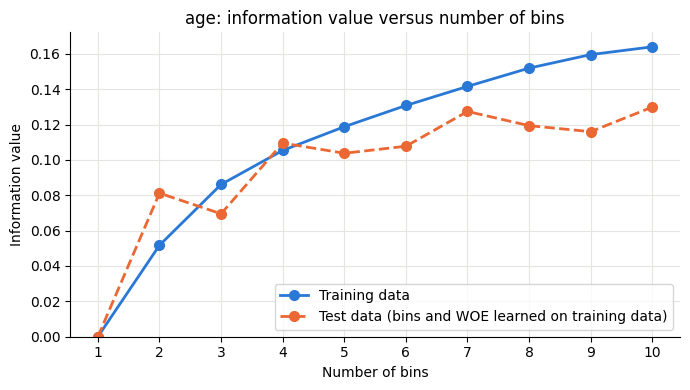

In [12]:
def plot_iv_curve(results, xlabel, title):
    """IV versus the number of categories: in-sample (training) and on new data (test)."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(results.index, results['IV (training)'], marker='o', markersize=7, linewidth=2, color=BLUE,
            label='Training data')
    ax.plot(results.index, results['IV (test, training WOE)'], marker='o', markersize=7, linewidth=2,
            linestyle='--', color=ORANGE, label='Test data (bins and WOE learned on training data)')
    ax.set_xticks(results.index)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Information value')
    ax.set_title(title)
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


plot_iv_curve(age_results, 'Number of bins', 'age: information value versus number of bins')

### Choosing the number of bins — your call

By construction, the training IV never decreases when a bin is added, so it cannot tell us when to stop. What helps is to look at the **gain** per extra bin (the table above) and at the shape of the curve: where do additional bins stop adding much predictive power — the "elbow"? The test IV adds a second perspective: it shows how much of the training IV survives on new customers, and it need not increase with the number of bins. The more bins, the fewer customers per bin, the less stable the WOE values.

This is a judgment call that balances simplicity and robustness (few bins) against predictive power (many bins). Here we go for four bins: with the default settings the gain per extra bin falls from about 0.034 (third bin) to 0.019 (fourth bin) and to 0.013 or less from the fifth bin on, so the extra bins buy little for the added complexity. The test IV is noisy — it moves up and down by a few hundredths from one number of bins to the next — a reminder of how unstable the WOE values of small bins are when they are estimated on a few hundred customers. Change `K_AGE` and re-run the notebook to see the consequences of another choice.

In [13]:
K_AGE = 4

iv_age, age_cutoffs = optimal_bins(train['age'], train['bad'], K_AGE)
age_bins_train = apply_bins(train['age'], age_cutoffs, 'age')
age_table = woe_table(age_bins_train, train['bad'])

print(f"{K_AGE} bins for age, cut-offs: {', '.join(f'{c:g}' for c in age_cutoffs)}   IV = {iv_age:.4f} ({iv_label(iv_age)})")
show_woe(age_table)

4 bins for age, cut-offs: 25, 34, 52   IV = 0.1053 (medium)


,Count,Distr. Count,Goods,Distr. Goods,Bads,Distr. Bads,Odds,WOE,IV
group,,,,,,,,,
age ≤ 25,124,17.7%,74,15.1%,50,23.8%,1.48,-45.5,0.0396
25 < age ≤ 34,261,37.3%,179,36.5%,82,39.0%,2.18,-6.7,0.0017
34 < age ≤ 52,254,36.3%,198,40.4%,56,26.7%,3.54,41.6,0.0571
age > 52,61,8.7%,39,8.0%,22,10.5%,1.77,-27.5,0.0069
Total,700,100.0%,490,100.0%,210,100.0%,,,0.1053


In [ ]:
def plot_woe(table, title, wrap=32):
    """Horizontal bar chart of the WOE per category / bin: positive = lower risk, negative = higher risk."""
    t = table.drop(index='Total', errors='ignore')
    labels = [textwrap.fill(str(name), wrap) for name in t.index][::-1]     # first category on top
    values = t['WOE'].to_numpy()[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.65 * len(t) + 1.8))
    ax.barh(labels, values, color=[BLUE if v >= 0 else ORANGE for v in values], height=0.6)
    ax.axvline(0, color='#52514e', linewidth=1)
    for y, v in enumerate(values):
        ax.text(v + (2 if v >= 0 else -2), y, f'{v:.0f}', va='center', ha='left' if v >= 0 else 'right')
    ax.margins(x=0.15)
    ax.grid(axis='y', visible=False)
    ax.set_xlabel('Weight of evidence (WOE × 100)')
    ax.set_title(title)
    ax.legend(handles=[Patch(color=BLUE, label='WOE > 0: relatively more goods (lower risk)'),
                       Patch(color=ORANGE, label='WOE < 0: relatively more bads (higher risk)')],
              loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=1, frameon=False)
    plt.tight_layout()
    plt.show()


plot_woe(age_table, 'age: WOE per bin')

Note what the bins reveal about the relation between age and risk. The WOE is not simply increasing (or decreasing) with age: the youngest bin carries the highest risk, the risk improves for the middle bin(s), and the pattern can turn around again for the oldest customers. A single coefficient on the raw age variable in a linear or logistic regression can only describe a straight-line relation. With one WOE value per bin, the same model captures this non-linear pattern, and the model stays interpretable: every age bin has its own, readable contribution to the score.

## 4. A categorical variable: `purpose`

The loan purpose has ten categories. With dummy encoding this means nine dummy variables — and dummy variables lead to instability: many parameters, each estimated on few customers. We can reduce the number of dummies by **regrouping the categories** into fewer groups. WOE then needs just one variable instead of a set of dummies.

First the WOE table of all ten categories, sorted from most risky (lowest WOE) to least risky:

In [14]:
purpose_table = woe_table(train['purpose'], train['bad'])
purpose_iv_all = purpose_table.loc['Total', 'IV']
print(f"Information value of 'purpose' with all categories: {purpose_iv_all:.4f}  ->  {iv_label(purpose_iv_all)}")

body = purpose_table.drop(index='Total').sort_values('WOE')
show_woe(pd.concat([body, purpose_table.loc[['Total']]]))

Information value of 'purpose' with all categories: 0.1322  ->  medium


,Count,Distr. Count,Goods,Distr. Goods,Bads,Distr. Bads,Odds,WOE,IV
group,,,,,,,,,
education,35,5.0%,17,3.5%,18,8.6%,0.94,-90.4,0.0461
repairs,16,2.3%,10,2.0%,6,2.9%,1.67,-33.6,0.0027
business,69,9.9%,45,9.2%,24,11.4%,1.88,-21.9,0.0049
new car,171,24.4%,113,23.1%,58,27.6%,1.95,-18.0,0.0082
other,6,0.9%,4,0.8%,2,1.0%,2.00,-15.4,0.0002
furniture/equipment,126,18.0%,85,17.3%,41,19.5%,2.07,-11.8,0.0026
domestic appliance,10,1.4%,7,1.4%,3,1.4%,2.33,0.0,0.0000
radio/tv,186,26.6%,144,29.4%,42,20.0%,3.43,38.5,0.0361
retraining,5,0.7%,4,0.8%,1,0.5%,4.00,53.9,0.0018


Look at the small categories (see the `Count` column). The WOE of a category with a handful of customers rests on a handful of observations: one more bad or one more good would change it noticeably. These are the unstable WOE values warned about in class — and one reason to regroup.

### IV-driven regrouping

Regrouping works exactly like binning, once the categories are put in a sensible order:

- Sort the categories by **risk** (their share of bads, equivalently their WOE). Categories that are neighbours in this order have similar risk, and these are the ones worth combining. It can be shown that, for a measure like the IV, an optimal grouping only ever combines categories that are neighbours in this order — so the search can be limited to groups of neighbours.
- The categories now play the role of the "atoms" that the distinct age values played above, and the same dynamic programming function finds the grouping with the highest IV for a given number of groups — again with the stability constraint of at least 5% of the customers per group.
- As in the slides on coarse classification, we also report the **chi-squared statistic** of the resulting table of goods and bads per group (higher = the distributions of goods and bads differ more across the groups). For $k$ groups it can be compared with a chi-squared distribution with $k-1$ degrees of freedom.

In [15]:
def categorical_atoms(x, bad):
    """Categories of x sorted from riskiest to safest, with their number of goods and bads."""
    t = pd.DataFrame({'x': np.asarray(x), 'bad': np.asarray(bad)}).groupby('x')['bad'].agg(n='size', bads='sum')
    t['goods'] = t['n'] - t['bads']
    t['bad_rate'] = t['bads'] / t['n']
    t = t.sort_values('bad_rate', ascending=False)
    return list(t.index), t['goods'].to_numpy(), t['bads'].to_numpy()


def optimal_regrouping(x, bad, k, min_fraction=MIN_FRACTION):
    """IV-optimal regrouping of the categories of x in k groups. Returns (iv, groups)."""
    categories, goods, bads = categorical_atoms(x, bad)
    iv, starts = optimal_grouping(goods, bads, k, min_count=min_count_for(len(x), min_fraction))
    if iv is None:
        return None, None
    ends = starts[1:] + [len(categories)]
    return iv, [categories[s:e] for s, e in zip(starts, ends)]


def apply_regrouping(x, groups):
    """Replace every category by the name of its group (the categories of the group, joined by ' + ')."""
    return x.map({category: ' + '.join(group) for group in groups for category in group})

### How many groups? Increase the number step by step and monitor the IV

In [16]:
rows = []
for k in range(1, 11):
    iv_k, groups = optimal_regrouping(train['purpose'], train['bad'], k)
    if iv_k is None:
        print(f"No valid regrouping with {k} groups: some groups would contain less than {MIN_FRACTION:.0%} of the customers.")
        break
    grouped_train = apply_regrouping(train['purpose'], groups)
    grouped_test = apply_regrouping(test['purpose'], groups)
    assert grouped_test.notna().all()                                  # no unseen categories in the test data
    woe_k = woe_table(grouped_train, train['bad'], total=False)
    assert np.isclose(iv_k, woe_k['IV'].sum())
    counts = pd.crosstab(grouped_train, train['bad']).to_numpy()
    rows.append({
        '# groups': k,
        'IV (training)': iv_k,
        'Gain vs. k-1': iv_k - rows[-1]['IV (training)'] if rows else np.nan,
        'IV (test, training WOE)': out_of_sample_iv(grouped_test, test['bad'], woe_k['WOE']),
        'Chi-squared (training)': chi2_contingency(counts, correction=False)[0] if k > 1 else np.nan,
        'Groups': ' | '.join('{' + ', '.join(group) + '}' for group in groups),
    })

purpose_results = pd.DataFrame(rows).set_index('# groups')
purpose_results.style.format({'IV (training)': '{:.4f}', 'Gain vs. k-1': '{:+.4f}', 'IV (test, training WOE)': '{:.4f}',
                              'Chi-squared (training)': '{:.1f}'}, na_rep='')

No valid regrouping with 7 groups: some groups would contain less than 5% of the customers.


,IV (training),Gain vs. k-1,"IV (test, training WOE)",Chi-squared (training),Groups
# groups,,,,,
1,0.0000,,0.0000,,"{education, repairs, business, new car, other, furniture/equipment, domestic appliance, radio/tv, retraining, used car}"
2,0.1003,+0.1003,0.1642,14.1,"{education, repairs, business, new car, other, furniture/equipment, domestic appliance} | {radio/tv, retraining, used car}"
3,0.1283,+0.0279,0.1427,18.9,"{education} | {repairs, business, new car, other, furniture/equipment, domestic appliance} | {radio/tv, retraining, used car}"
4,0.1304,+0.0021,0.1501,19.1,"{education} | {repairs, business, new car, other, furniture/equipment, domestic appliance} | {radio/tv} | {retraining, used car}"
5,0.1315,+0.0011,0.1552,19.3,"{education} | {repairs, business, new car} | {other, furniture/equipment, domestic appliance} | {radio/tv} | {retraining, used car}"
6,0.1318,+0.0003,0.1535,19.4,"{education} | {repairs, business} | {new car, other} | {furniture/equipment, domestic appliance} | {radio/tv} | {retraining, used car}"


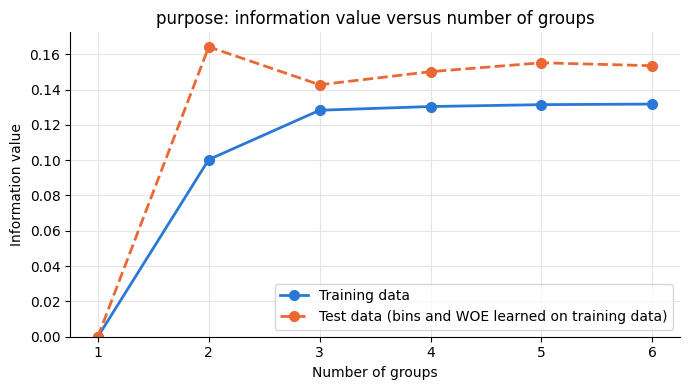

In [17]:
plot_iv_curve(purpose_results, 'Number of groups', 'purpose: information value versus number of groups')

### Optional check: is searching only groups of neighbours enough?

The search above only considers groups of categories that are neighbours in the risk order, and applies a minimum group size. To verify that this does not miss a better grouping, we can simply try **every possible way** of splitting the ten categories into $k$ groups (there are tens of thousands for a given $k$) and keep the best one that satisfies the same constraint.

In [18]:
def set_partitions(n, k):
    """All ways to split n items in exactly k non-empty groups (as a group number for every item)."""
    def build(i, labels, used):
        if i == n:
            if used == k:
                yield tuple(labels)
            return
        if used + (n - i) < k:                       # not enough items left to open the missing groups
            return
        for g in range(min(used + 1, k)):
            labels.append(g)
            yield from build(i + 1, labels, max(used, g + 1))
            labels.pop()
    yield from build(0, [], 0)


def exhaustive_best_iv(goods, bads, k, min_count):
    """Best IV over all ways to group the atoms in k groups (the same constraints as optimal_grouping)."""
    goods, bads = np.asarray(goods, float), np.asarray(bads, float)
    G, B = goods.sum(), bads.sum()
    best = -np.inf
    for labels in set_partitions(len(goods), k):
        labels = np.array(labels)
        g = np.bincount(labels, weights=goods, minlength=k)
        b = np.bincount(labels, weights=bads, minlength=k)
        if (g + b < min_count).any() or (g == 0).any() or (b == 0).any():
            continue
        best = max(best, np.sum((g / G - b / B) * np.log((g / G) / (b / B))))
    return best


_, goods_c, bads_c = categorical_atoms(train['purpose'], train['bad'])
check = pd.DataFrame({
    'IV, groups of neighbours': purpose_results['IV (training)'],
    'IV, all possible groupings': [exhaustive_best_iv(goods_c, bads_c, k, min_count_for(len(train)))
                                   for k in purpose_results.index],
})
check['Same?'] = np.where(np.isclose(check.iloc[:, 0], check.iloc[:, 1]), '✓', '✗')
check.round(4)

,"IV, groups of neighbours","IV, all possible groupings",Same?
# groups,,,
1,0.0000,0.0000,✓
2,0.1003,0.1003,✓
3,0.1283,0.1283,✓
4,0.1304,0.1304,✓
5,0.1315,0.1315,✓
6,0.1318,0.1318,✓


### Choosing the number of groups — your call

Again: the training IV can only increase with the number of groups, so look at the gain per extra group and at the elbow of the curve. Here the elbow is clear: with the default settings the third group adds 0.028 to the IV, the fourth only 0.002, and the IV on the test data does not improve beyond two groups. Three groups retain almost all of the IV of the ten original categories, and, as the check above showed, there is no better way to form them. Note also that the stability constraint caps the number of groups that is possible at all.

In [19]:
K_PURPOSE = 3

iv_purpose, purpose_groups = optimal_regrouping(train['purpose'], train['bad'], K_PURPOSE)
purpose_grouped_train = apply_regrouping(train['purpose'], purpose_groups)
purpose_group_table = woe_table(purpose_grouped_train, train['bad'])

print(f"{K_PURPOSE} groups for purpose   IV = {iv_purpose:.4f} ({iv_label(iv_purpose)})"
      f"   (all {len(purpose_table) - 1} categories: IV = {purpose_iv_all:.4f})")
show_woe(purpose_group_table)

3 groups for purpose   IV = 0.1283 (medium)   (all 10 categories: IV = 0.1322)


,Count,Distr. Count,Goods,Distr. Goods,Bads,Distr. Bads,Odds,WOE,IV
group,,,,,,,,,
education,35,5.0%,17,3.5%,18,8.6%,0.94,-90.4,0.0461
radio/tv + retraining + used car,267,38.1%,209,42.7%,58,27.6%,3.60,43.5,0.0653
repairs + business + new car + other + furniture/equipment + domestic appliance,398,56.9%,264,53.9%,134,63.8%,1.97,-16.9,0.0168
Total,700,100.0%,490,100.0%,210,100.0%,,,0.1283


In [ ]:
plot_woe(purpose_group_table, 'purpose: WOE per group', wrap=36)

## 5. WOE encoding of the two variables

Now every bin or group is replaced by its WOE value, which turns each variable into **a single numeric variable**. The WOE values come from the **training** data and are applied unchanged to the test data.

In [20]:
age_woe = woe_table(age_bins_train, train['bad'], total=False)['WOE']
purpose_woe = woe_table(purpose_grouped_train, train['bad'], total=False)['WOE']

for data in (train, test):
    data['age_bin'] = apply_bins(data['age'], age_cutoffs, 'age').astype(str)
    data['purpose_group'] = apply_regrouping(data['purpose'], purpose_groups)
    data['age_woe'] = data['age_bin'].map(age_woe)
    data['purpose_woe'] = data['purpose_group'].map(purpose_woe)
    # A category that was not seen in the training data would get no WOE: decide on a rule for such cases
    # (for example a WOE of 0, or a separate "other / missing" group) before using the encoding in practice.
    assert data[['age_woe', 'purpose_woe']].notna().all().all()

test[['age', 'age_bin', 'age_woe', 'purpose', 'purpose_group', 'purpose_woe', 'bad']].head(8)

,age,age_bin,age_woe,purpose,purpose_group,purpose_woe,bad
0,47,34 < age ≤ 52,41.561748,radio/tv,radio/tv + retraining + used car,43.459338,0
1,23,age ≤ 25,-45.525577,radio/tv,radio/tv + retraining + used car,43.459338,0
2,31,25 < age ≤ 34,-6.663130,radio/tv,radio/tv + retraining + used car,43.459338,0
3,33,25 < age ≤ 34,-6.663130,radio/tv,radio/tv + retraining + used car,43.459338,0
4,21,age ≤ 25,-45.525577,furniture/equipment,repairs + business + new car + other + furniture/equipment + domestic appliance,-16.918856,0
5,57,age > 52,-27.477867,radio/tv,radio/tv + retraining + used car,43.459338,0
6,25,age ≤ 25,-45.525577,radio/tv,radio/tv + retraining + used car,43.459338,0
7,29,25 < age ≤ 34,-6.663130,used car,radio/tv + retraining + used car,43.459338,0


## 6. WOE encoding versus dummy encoding

We now use the variables in a logistic regression that predicts the probability of being a bad, in three ways:

- **A. Dummy encoding of the original variables:** `age` as it is, plus nine dummy variables for the ten `purpose` categories.
- **B. Dummy encoding of the optimized bins and groups:** dummy variables for the age bins and for the purpose groups.
- **C. WOE encoding of the optimized bins and groups:** one WOE variable per characteristic.

Comparing B and C isolates the effect of the encoding itself: same categories, but dummies need one parameter per category (minus one) while WOE needs just one parameter per variable. The logistic regression is fitted without regularization, so the number of parameters is the only difference in complexity.

In [21]:
def fit_and_evaluate(name, columns, dummy_columns=()):
    """Fit a logistic regression on the given columns (dummy-encoding the `dummy_columns`) and evaluate its AUC."""
    both = pd.concat([train[columns], test[columns]], keys=['train', 'test'])
    X = pd.get_dummies(both, columns=list(dummy_columns), drop_first=True, dtype=float)
    X_train, X_test = X.loc['train'], X.loc['test']
    model = LogisticRegression(C=1e6, max_iter=10000).fit(X_train, train['bad'])    # very large C = no regularization
    result = {
        'Encoding': name,
        '# parameters': X_train.shape[1] + 1,                                        # coefficients + intercept
        'AUC (training)': roc_auc_score(train['bad'], model.predict_proba(X_train)[:, 1]),
        'AUC (test)': roc_auc_score(test['bad'], model.predict_proba(X_test)[:, 1]),
    }
    return result, model, X_train


result_a, _, _ = fit_and_evaluate('A. Dummies, original variables', ['age', 'purpose'], dummy_columns=['purpose'])
result_b, _, _ = fit_and_evaluate('B. Dummies, optimized bins and groups', ['age_bin', 'purpose_group'],
                                  dummy_columns=['age_bin', 'purpose_group'])
result_c, model_woe, X_woe = fit_and_evaluate('C. WOE, optimized bins and groups', ['age_woe', 'purpose_woe'])

pd.DataFrame([result_a, result_b, result_c]).set_index('Encoding').round(3)

,# parameters,AUC (training),AUC (test)
Encoding,,,
"A. Dummies, original variables",11,0.61,0.683
"B. Dummies, optimized bins and groups",6,0.64,0.655
"C. WOE, optimized bins and groups",3,0.64,0.655


Things to look at in this table:

- The **number of parameters**: WOE encoding needs one parameter per variable, whatever the number of categories. Dummy encoding of the original variables needs one per category (minus one).
- The **AUC on the training and test data**. With only 300 customers in the test set, differences of a few hundredths in AUC are within the noise of this single split: re-run the notebook with another `RANDOM_STATE` to see how much the bins, the IV, the WOE values and the AUC move.

Finally, the coefficients of the WOE model. Since a positive WOE means *lower* risk and the model predicts the probability of a *bad*, the coefficients are negative. Expressed per unit of WOE/100 (the log of the ratio of the distributions of goods and bads), they are close to −1: the WOE value already expresses the contribution of the category to the log-odds, and the logistic regression only fine-tunes it to account for the overlap between the two variables.

In [22]:
pd.DataFrame({
    'Coefficient per WOE/100 unit': model_woe.coef_[0] * 100,
}, index=X_woe.columns).round(3)

,Coefficient per WOE/100 unit
age_woe,-1.036
purpose_woe,-1.029


## Wrap-up

- **WOE** replaces every category by `ln(Distr. Goods / Distr. Bads) × 100`: negative for risky categories, positive for safe ones, and independent of the class distribution. One WOE variable replaces a whole set of dummies.
- The **information value** summarizes the predictive power of a variable, and drives the choice of the categories: for a given number of categories the boundaries (continuous variable) or groups (categorical variable) are the ones that maximize the IV.
- The **number of categories** is a trade-off. IV can only go up with more categories; the question is where extra categories stop adding much, balancing simplicity and robustness against predictive power. Looking at the IV curve, the gain per extra category and the behaviour on test data supports that decision.

Natural next steps:
- Make the WOE values more robust with **Laplace smoothing** (`WOE = ln((Distr. Goods + n) / (Distr. Bads + n)) × 100`) or by using fewer categories, and test the stability of bins, IV and WOE values across different train/test splits.
- Require the WOE to be **monotone** across the bins of a continuous variable (often demanded in credit scoring), and compare the IV you give up.
- Calculate the IV of **all** variables and use it as a variable filter, then WOE-encode the selected ones.
- Use the WOE-encoded variables in a logistic regression on all selected variables and transform it into a **scorecard** in a post-processing step.